# 01 – Analyse exploratoire des deux jeux de données

**Mission Agritech Answers** – prédire le rendement d'une culture et recommander la culture la plus adaptée à une parcelle.

Ce notebook explore **chaque jeu séparément**, sans rien modifier aux fichiers sources. Les décisions de nettoyage et la fusion sont appliquées dans `02_fusion.ipynb`.

| Jeu | Fichier | Rôle prévu (option A retenue) |
|---|---|---|
| Agriculture Crop Yield (Kaggle) | `agriculture_crop_yield/crop_yield.csv` | mesurer l'effet des **pratiques** (engrais, irrigation) |
| Crop Yield Prediction Dataset (FAO / Banque mondiale) | `crop_yield_prediction/yield_df.csv` + sources | base du modèle : rendement **par culture** selon le climat et les pesticides |

Questions directrices :
1. Quelle est la qualité de chaque source (valeurs manquantes, doublons, valeurs impossibles) ?
2. Quelles variables expliquent le rendement dans chaque jeu ?
3. Les deux jeux sont-ils compatibles (cultures, unités, plages de valeurs) ?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from agritech_crop_reco.config import PROJECT_ROOT, load_settings
from agritech_crop_reco.data.load import load_crop_yield, load_fao_sources, load_fao_yield_df

settings = load_settings()
SEED = settings.seed
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.2f}".format)


def save(fig, name):
    """Sauvegarde la figure pour le rapport métier."""
    fig.savefig(FIG_DIR / f"01_{name}.png", dpi=120, bbox_inches="tight")

## Partie A – Agriculture Crop Yield (Kaggle)

### A1. Structure

In [2]:
crop = load_crop_yield()
TARGET = "Yield_tons_per_hectare"
NUM = ["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest"]
CAT = ["Region", "Soil_Type", "Crop", "Weather_Condition"]
BOOL = ["Fertilizer_Used", "Irrigation_Used"]

print(
    f"{crop.shape[0]:,} lignes × {crop.shape[1]} colonnes – "
    f"{crop.memory_usage(deep=True).sum() / 1e6:.0f} Mo en mémoire"
)
display(crop.dtypes.to_frame("type"))
crop.head()

1,000,000 lignes × 10 colonnes – 38 Mo en mémoire


,type
Region,category
Soil_Type,category
Crop,category
Rainfall_mm,float64
Temperature_Celsius,float64
Fertilizer_Used,bool
Irrigation_Used,bool
Weather_Condition,category
Days_to_Harvest,int64
Yield_tons_per_hectare,float64


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.08,27.68,False,True,Cloudy,122,6.56
1,South,Clay,Rice,992.67,18.03,True,True,Rainy,140,8.53
2,North,Loam,Barley,148.00,29.79,False,False,Sunny,106,1.13
3,North,Sandy,Soybean,986.87,16.64,False,True,Rainy,146,6.52
4,South,Silt,Wheat,730.38,31.62,True,True,Cloudy,110,7.25


### A2. Qualité : valeurs manquantes, doublons, valeurs impossibles

In [3]:
quality_crop = pd.Series(
    {
        "valeurs manquantes": int(crop.isna().sum().sum()),
        "lignes dupliquées": int(crop.duplicated().sum()),
        "rendement ≤ 0 t/ha": int((crop[TARGET] <= 0).sum()),
    }
)
display(quality_crop.to_frame("nombre"))
crop.describe().T

,nombre
valeurs manquantes,0
lignes dupliquées,0
rendement ≤ 0 t/ha,231


,count,mean,std,min,25%,50%,75%,max
Rainfall_mm,"1,000,000.00",549.98,259.85,100.00,324.89,550.12,774.74,"1,000.00"
Temperature_Celsius,"1,000,000.00",27.50,7.22,15.00,21.25,27.51,33.75,40.00
Days_to_Harvest,"1,000,000.00",104.50,25.95,60.00,82.00,104.00,127.00,149.00
Yield_tons_per_hectare,"1,000,000.00",4.65,1.70,-1.15,3.42,4.65,5.88,9.96


In [4]:
# Qui sont les rendements négatifs ?
neg = crop[crop[TARGET] <= 0]
display(neg[NUM + [TARGET]].describe().T[["count", "mean", "min", "max"]])
display(neg[BOOL].mean().to_frame("part de True"))

,count,mean,min,max
Rainfall_mm,231.00,134.83,100.30,235.79
Temperature_Celsius,231.00,22.68,15.05,39.79
Days_to_Harvest,231.00,103.99,60.00,149.00
Yield_tons_per_hectare,231.00,-0.20,-1.15,-0.00


,part de True
Fertilizer_Used,0.00
Irrigation_Used,0.00


**Lecture.** Aucune valeur manquante ni doublon. Seule anomalie : des rendements **négatifs ou nuls**, physiquement impossibles. Les 231 cas cumulent **pluie très faible** (≤ 236 mm) **et aucune pratique** (ni engrais, ni irrigation) : le générateur du jeu calcule visiblement le rendement par une formule qui devient négative quand la pluie est très faible.

➡️ *Décision pour 02* : supprimer ces lignes (0,02 % du jeu) plutôt que les ramener à 0, ce qui créerait un pic artificiel.

### A3. Distributions des variables

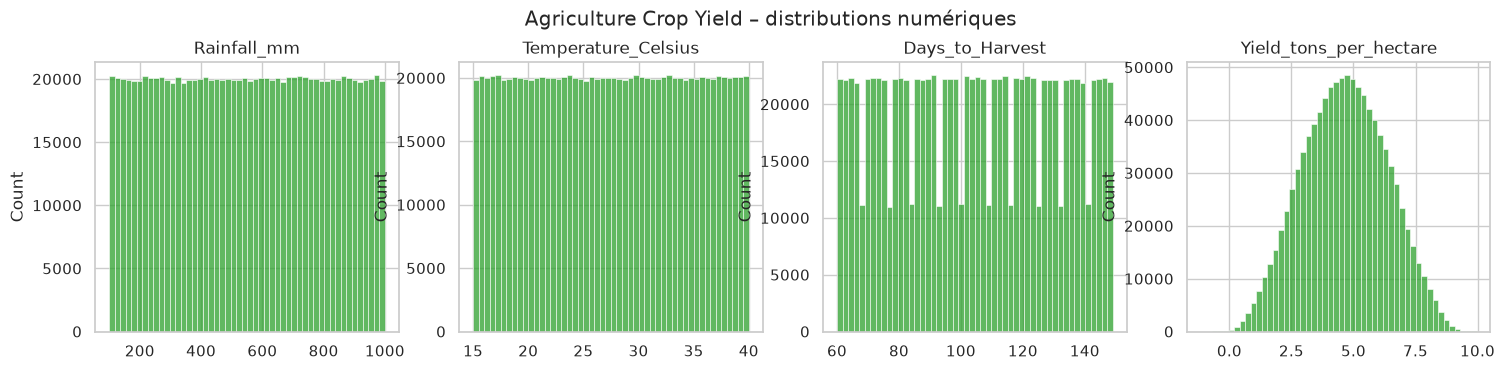

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, col in zip(axes, NUM + [TARGET], strict=True):
    sns.histplot(crop[col], bins=50, ax=ax, color="tab:green")
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Agriculture Crop Yield – distributions numériques", y=1.03)
save(fig, "kaggle_distributions_num")
plt.show()

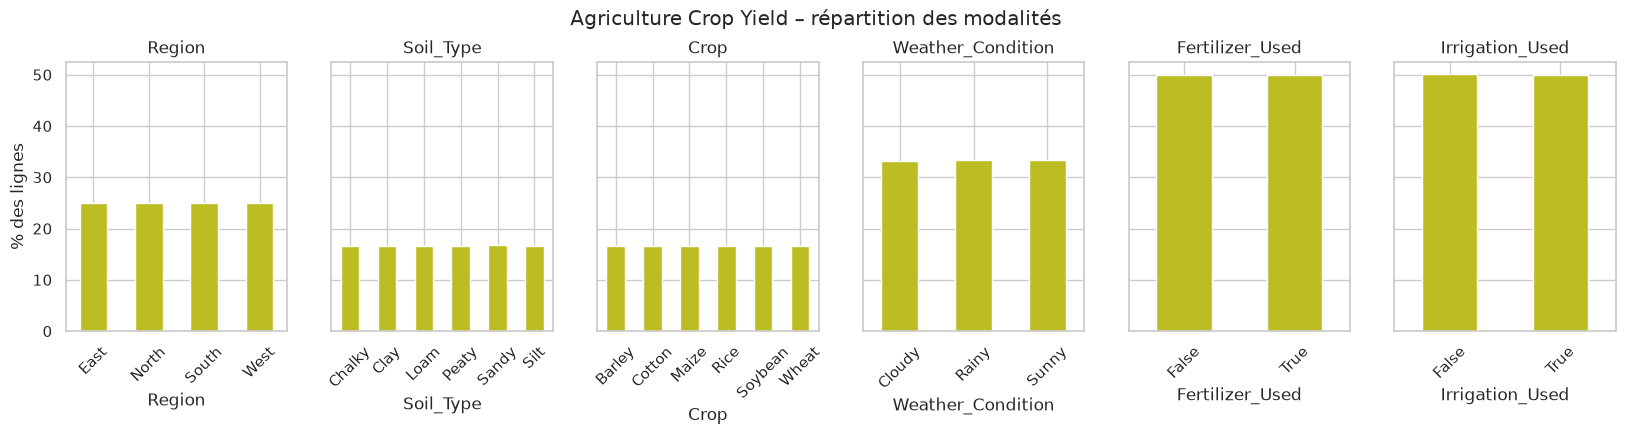

In [6]:
fig, axes = plt.subplots(1, 6, figsize=(20, 3.5), sharey=True)
for ax, col in zip(axes, CAT + BOOL, strict=True):
    shares = crop[col].value_counts(normalize=True).sort_index() * 100
    shares.plot.bar(ax=ax, color="tab:olive")
    ax.set_title(col)
    ax.set_ylabel("% des lignes")
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Agriculture Crop Yield – répartition des modalités", y=1.03)
save(fig, "kaggle_distributions_cat")
plt.show()

**Lecture.** Pluie, température et durée de culture sont **uniformes** sur leur intervalle (histogrammes plats), et chaque modalité est représentée à parts quasi égales (6 cultures ≈ 16,7 % chacune, engrais et irrigation ≈ 50 %). Des données réelles ne sont jamais aussi régulières : **ce jeu est synthétique**. Le rendement, lui, a une forme en cloche, comme s'il était obtenu en combinant plusieurs variables uniformes.

➡️ Les conclusions tirées de ce jeu décrivent **la logique du simulateur**, pas une réalité agronomique : c'est une limite à assumer dans le rapport.

### A4. Qu'est-ce qui fait varier le rendement ?

In [7]:
effects = []
for col in CAT + BOOL:
    means = crop.groupby(col, observed=True)[TARGET].mean()
    effects.append(
        {
            "variable": col,
            "écart max entre modalités (t/ha)": means.max() - means.min(),
            "moyennes": means.round(2).to_dict(),
        }
    )
effects = pd.DataFrame(effects).sort_values("écart max entre modalités (t/ha)", ascending=False)
effects

,variable,écart max entre modalités (t/ha),moyennes
4,Fertilizer_Used,1.50,"{False: 3.9, True: 5.4}"
5,Irrigation_Used,1.20,"{False: 4.05, True: 5.25}"
2,Crop,0.01,"{'Barley': 4.65, 'Cotton': 4.65, 'Maize': 4.64..."
0,Region,0.01,"{'East': 4.65, 'North': 4.65, 'South': 4.65, '..."
1,Soil_Type,0.01,"{'Chalky': 4.65, 'Clay': 4.64, 'Loam': 4.65, '..."
3,Weather_Condition,0.00,"{'Cloudy': 4.65, 'Rainy': 4.65, 'Sunny': 4.65}"


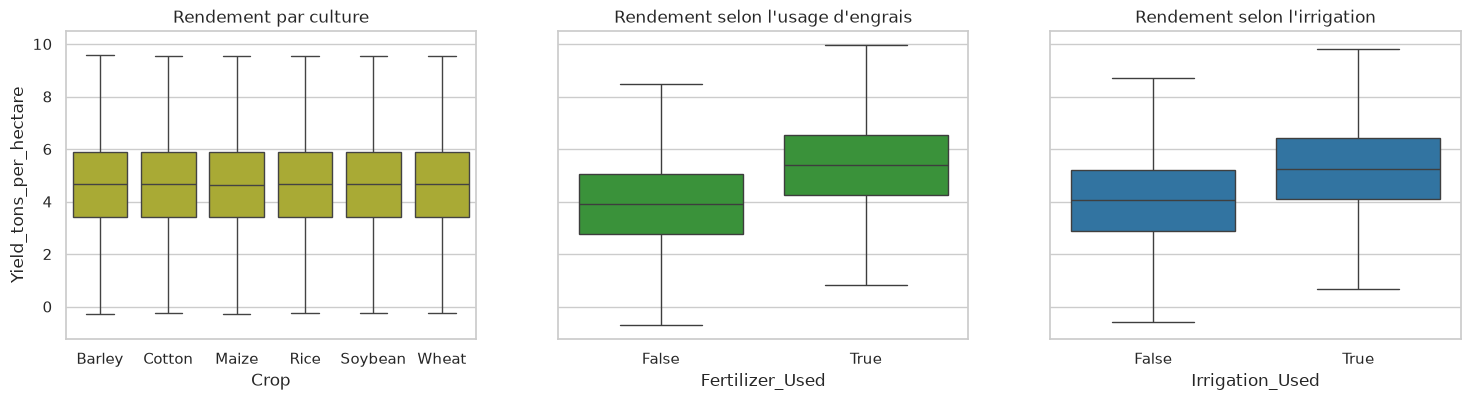

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
sns.boxplot(data=crop, x="Crop", y=TARGET, ax=axes[0], color="tab:olive", showfliers=False)
axes[0].set_title("Rendement par culture")
sns.boxplot(
    data=crop, x="Fertilizer_Used", y=TARGET, ax=axes[1], color="tab:green", showfliers=False
)
axes[1].set_title("Rendement selon l'usage d'engrais")
sns.boxplot(
    data=crop, x="Irrigation_Used", y=TARGET, ax=axes[2], color="tab:blue", showfliers=False
)
axes[2].set_title("Rendement selon l'irrigation")
save(fig, "kaggle_yield_by_crop_practices")
plt.show()

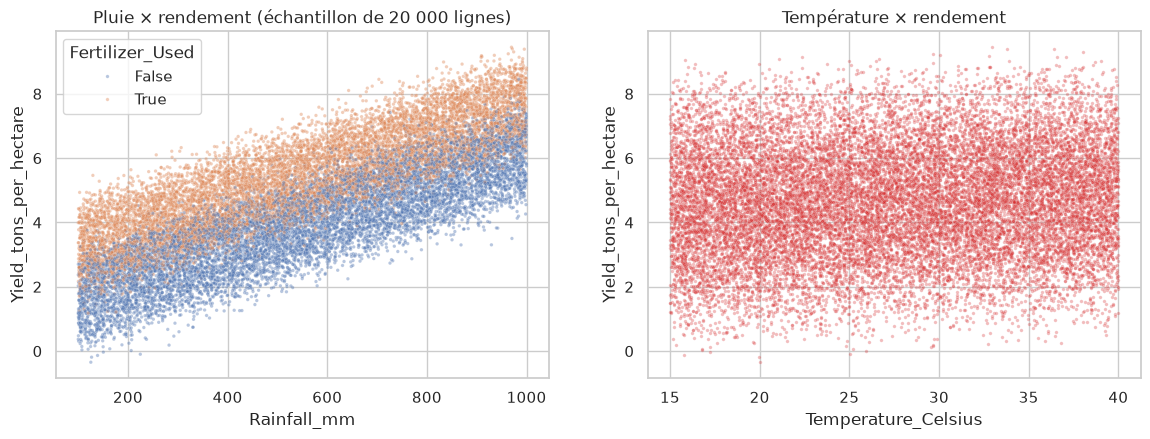

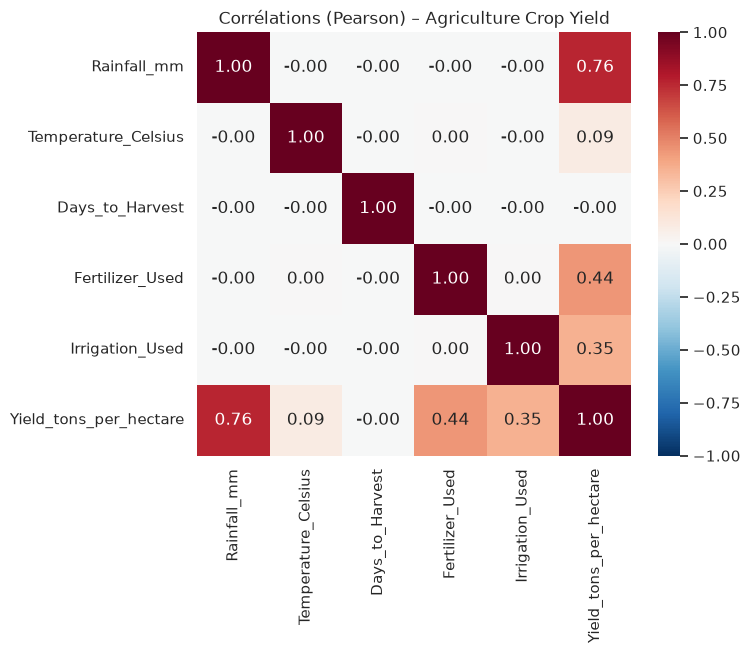

In [9]:
sample = crop.sample(20_000, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(
    data=sample, x="Rainfall_mm", y=TARGET, hue="Fertilizer_Used", s=6, alpha=0.4, ax=axes[0]
)
axes[0].set_title("Pluie × rendement (échantillon de 20 000 lignes)")
sns.scatterplot(
    data=sample, x="Temperature_Celsius", y=TARGET, s=6, alpha=0.3, color="tab:red", ax=axes[1]
)
axes[1].set_title("Température × rendement")
save(fig, "kaggle_scatter_rain_temp")
plt.show()

corr = crop[NUM + BOOL + [TARGET]].astype(float).corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Corrélations (Pearson) – Agriculture Crop Yield")
save(fig, "kaggle_corr")
plt.show()

In [10]:
# Effet relatif des pratiques : base du « facteur pratiques » de l'option A
practice_effect = pd.DataFrame(
    {
        col: {
            "rendement sans (t/ha)": crop.loc[~crop[col], TARGET].mean(),
            "rendement avec (t/ha)": crop.loc[crop[col], TARGET].mean(),
        }
        for col in BOOL
    }
).T
practice_effect["gain absolu (t/ha)"] = practice_effect.diff(axis=1).iloc[:, -1]
practice_effect["gain relatif (%)"] = (
    practice_effect["gain absolu (t/ha)"] / practice_effect["rendement sans (t/ha)"] * 100
)
practice_effect

,rendement sans (t/ha),rendement avec (t/ha),gain absolu (t/ha),gain relatif (%)
Fertilizer_Used,3.90,5.40,1.50,38.47
Irrigation_Used,4.05,5.25,1.20,29.64


In [11]:
# Le gain est-il le même pour chaque culture ? (justifie de l'appliquer à toutes les cultures FAO)
gain_by_crop = (
    crop.groupby(["Crop", "Fertilizer_Used"], observed=True)[TARGET]
    .mean()
    .unstack()
    .rename(columns={False: "sans engrais", True: "avec engrais"})
)
gain_by_crop["gain engrais (%)"] = (
    gain_by_crop["avec engrais"] / gain_by_crop["sans engrais"] - 1
) * 100
irr = crop.groupby(["Crop", "Irrigation_Used"], observed=True)[TARGET].mean().unstack()
gain_by_crop["gain irrigation (%)"] = (irr[True] / irr[False] - 1) * 100
gain_by_crop

Fertilizer_Used,sans engrais,avec engrais,gain engrais (%),gain irrigation (%)
Crop,,,,
Barley,3.89,5.41,38.91,29.46
Cotton,3.90,5.40,38.32,29.57
Maize,3.90,5.39,38.33,29.87
Rice,3.90,5.40,38.48,29.74
Soybean,3.91,5.40,38.28,29.87
Wheat,3.90,5.40,38.48,29.31


**Lecture.**
- La **culture, la région, le type de sol et la météo n'ont aucun effet** : les moyennes par modalité diffèrent de quelques centièmes de tonne, soit du bruit.
- Le rendement est porté par **trois leviers** : la **pluie** (relation linéaire très nette), l'**engrais** et l'**irrigation**. La température a un effet faible ; la durée de culture aucun.
- Le gain relatif dû à l'engrais et à l'irrigation est **pratiquement identique pour les 6 cultures**.

➡️ Conséquences :
1. Ce jeu **ne permet pas de recommander une culture plutôt qu'une autre** : toutes ont le même rendement attendu. C'est ce qui justifie l'option A (modèle principal sur les données FAO).
2. Il fournit en revanche une **mesure propre de l'effet des pratiques** (engrais, irrigation), que les données FAO n'ont pas. Comme cet effet ne dépend pas de la culture, on peut l'appliquer aux cultures FAO absentes de ce jeu.

## Partie B – Crop Yield Prediction Dataset (FAO / Banque mondiale)

`yield_df.csv` est un fichier **déjà fusionné** par l'auteur du jeu à partir de 4 sources : rendements FAO (`yield.csv`), pesticides FAO (`pesticides.csv`), pluie Banque mondiale (`rainfall.csv`) et températures (`temp.csv`). On l'explore, puis on contrôle comment il a été construit.

### B1. Structure

In [12]:
fao = load_fao_yield_df()
KEYS = ["Area", "Item", "Year"]
FAO_TARGET = "hg/ha_yield"
FAO_NUM = ["average_rain_fall_mm_per_year", "pesticides_tonnes", "avg_temp"]

print(f"{fao.shape[0]:,} lignes × {fao.shape[1]} colonnes")
print(
    f"{fao['Area'].nunique()} pays, {fao['Item'].nunique()} cultures, "
    f"années {fao['Year'].min()}–{fao['Year'].max()}"
)
display(fao.head())
fao.describe().T

28,242 lignes × 7 colonnes
101 pays, 10 cultures, années 1990–2013


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,Albania,Maize,1990,36613,"1,485.00",121.00,16.37
1,Albania,Potatoes,1990,66667,"1,485.00",121.00,16.37
2,Albania,"Rice, paddy",1990,23333,"1,485.00",121.00,16.37
3,Albania,Sorghum,1990,12500,"1,485.00",121.00,16.37
4,Albania,Soybeans,1990,7000,"1,485.00",121.00,16.37


,count,mean,std,min,25%,50%,75%,max
Year,"28,242.00","2,001.54",7.05,"1,990.00","1,995.00","2,001.00","2,008.00","2,013.00"
hg/ha_yield,"28,242.00","77,053.33","84,956.61",50.00,"19,919.25","38,295.00","104,676.75","501,412.00"
average_rain_fall_mm_per_year,"28,242.00","1,149.06",709.81,51.00,593.00,"1,083.00","1,668.00","3,240.00"
pesticides_tonnes,"28,242.00","37,076.91","59,958.78",0.04,"1,702.00","17,529.44","48,687.88","367,778.00"
avg_temp,"28,242.00",20.54,6.31,1.30,16.70,21.51,26.00,30.65


### B2. Qualité : doublons

In [13]:
quality_fao = pd.Series(
    {
        "valeurs manquantes": int(fao.isna().sum().sum()),
        "lignes strictement dupliquées": int(fao.duplicated().sum()),
        "doublons sur la clé pays × culture × année": int(fao.duplicated(KEYS).sum()),
        "combinaisons pays × culture × année uniques": int((~fao.duplicated(KEYS)).sum()),
    }
)
quality_fao.to_frame("nombre")

,nombre
valeurs manquantes,0
lignes strictement dupliquées,2310
doublons sur la clé pays × culture × année,15112
combinaisons pays × culture × année uniques,13130


In [14]:
# Un exemple de clé dupliquée : seule la température change
example = fao[fao.duplicated(KEYS, keep=False)].sort_values(KEYS)
first_key = example.iloc[0][KEYS].tolist()
display(example[(example[KEYS] == first_key).all(axis=1)])

dup_by_country = (
    fao.groupby(KEYS)
    .size()
    .rename("lignes par clé")
    .reset_index()
    .groupby("Area")["lignes par clé"]
    .max()
    .sort_values(ascending=False)
)
dup_by_country.head(10).to_frame("max de lignes pour une même clé")

,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
377,Argentina,Cassava,1990,100000,591.00,"26,156.00",17.46
378,Argentina,Cassava,1990,100000,591.00,"26,156.00",17.67


,max de lignes pour une même clé
Area,
India,22
Brazil,11
Pakistan,9
Mexico,8
Australia,6
Japan,6
Canada,6
Indonesia,6
United Kingdom,5


In [15]:
# Origine : temp.csv contient plusieurs relevés par pays et par année
src = load_fao_sources()
temp = src["temp"]
per_country_year = temp.groupby(["country", "year"]).size()
print(f"temp.csv : {len(temp):,} lignes, {temp['avg_temp'].isna().sum():,} températures manquantes")
med, mx = per_country_year.median(), per_country_year.max()
print(f"relevés par pays × année : médiane {med:.0f}, max {mx}")
per_country_year.groupby("country").max().sort_values(ascending=False).head(8).to_frame(
    "relevés max / an"
)

temp.csv : 71,311 lignes, 2,547 températures manquantes
relevés par pays × année : médiane 1, max 52


,relevés max / an
country,
United States,52
China,34
India,22
Brazil,11
Russia,9
Pakistan,9
Mexico,8
Nigeria,7


**Lecture.** Le fichier compte **28 242 lignes mais seulement environ la moitié de situations distinctes** (pays × culture × année). La cause est dans `temp.csv` : pour les grands pays, il y a **plusieurs relevés de température par an** (une station par ville). Lors de la fusion d'origine, chaque relevé a démultiplié la ligne de rendement : jusqu'à 22 copies de la même observation pour l'Inde, 11 pour le Brésil, 9 pour le Pakistan. Résultat : les mêmes rendements sont comptés plusieurs fois, et **les grands pays pèsent artificiellement plus** dans le jeu.

➡️ *Décision pour 02* : ramener chaque clé pays × culture × année à **une seule ligne**, en prenant la **moyenne des températures** (les autres colonnes sont identiques au sein d'une clé — vérifié ci-dessous). Ce dédoublonnage doit être fait **avant** tout découpage entraînement / test, sinon une même observation se retrouverait des deux côtés (fuite de données).

In [16]:
# Vérification : au sein d'une clé, seules les températures varient
n_values = fao.groupby(KEYS)[
    [FAO_TARGET, "average_rain_fall_mm_per_year", "pesticides_tonnes", "avg_temp"]
].nunique()
(n_values > 1).sum().to_frame("clés où la colonne varie")

,clés où la colonne varie
hg/ha_yield,0
average_rain_fall_mm_per_year,0
pesticides_tonnes,0
avg_temp,3690


In [17]:
# Version dédoublonnée utilisée pour la suite de l'exploration
fao_u = fao.groupby(KEYS, as_index=False).agg(
    {
        FAO_TARGET: "first",
        "average_rain_fall_mm_per_year": "first",
        "pesticides_tonnes": "first",
        "avg_temp": "mean",
    }
)
fao_u["yield_t_ha"] = fao_u[FAO_TARGET] / 10_000  # 1 t = 10 000 hg
print(f"{len(fao):,} → {len(fao_u):,} lignes après dédoublonnage")

28,242 → 13,130 lignes après dédoublonnage


### B3. Unités et distribution du rendement

Le rendement FAO est en **hectogrammes par hectare** (hg/ha) : 1 hg = 100 g, donc **1 t/ha = 10 000 hg/ha**. On le convertit en t/ha pour être comparable au jeu Kaggle.

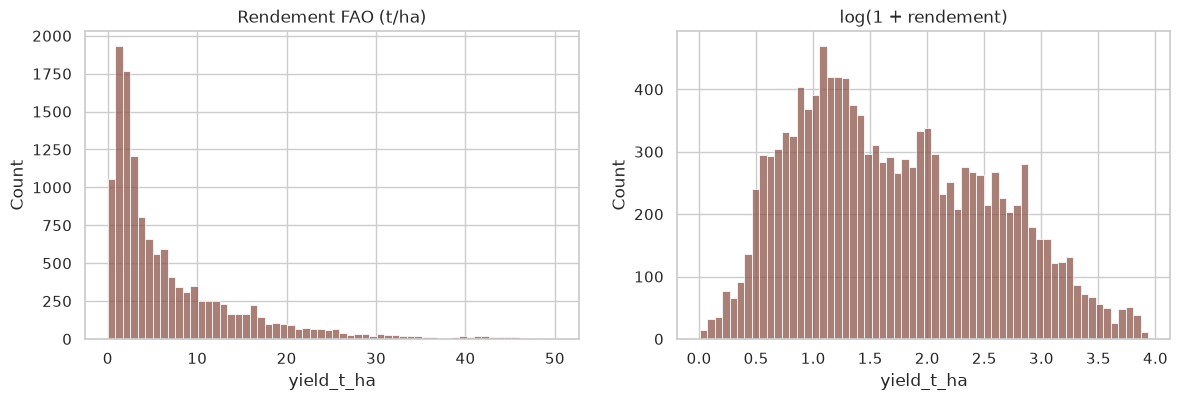

asymétrie : brute 2.08 | log 0.36


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(fao_u["yield_t_ha"], bins=60, ax=axes[0], color="tab:brown")
axes[0].set_title("Rendement FAO (t/ha)")
sns.histplot(np.log1p(fao_u["yield_t_ha"]), bins=60, ax=axes[1], color="tab:brown")
axes[1].set_title("log(1 + rendement)")
save(fig, "fao_yield_distribution")
plt.show()
skew_raw, skew_log = fao_u["yield_t_ha"].skew(), np.log1p(fao_u["yield_t_ha"]).skew()
print(f"asymétrie : brute {skew_raw:.2f} | log {skew_log:.2f}")

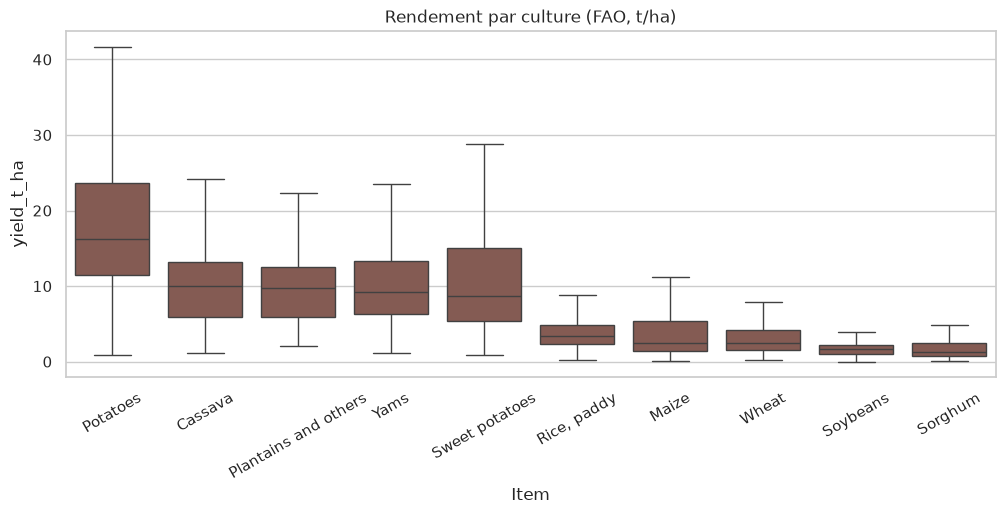

,lignes,pays,rendement_median_t_ha
Item,,,
Potatoes,2091,95,16.19
Cassava,941,41,10.00
Plantains and others,464,21,9.70
Yams,454,21,9.24
Sweet potatoes,1163,53,8.75
"Rice, paddy",1502,68,3.36
Maize,2028,92,2.45
Wheat,1810,82,2.43
Soybeans,1242,58,1.62


In [19]:
order = fao_u.groupby("Item")["yield_t_ha"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(
    data=fao_u, x="Item", y="yield_t_ha", order=order, ax=ax, color="tab:brown", showfliers=False
)
ax.set_title("Rendement par culture (FAO, t/ha)")
ax.tick_params(axis="x", rotation=30)
save(fig, "fao_yield_by_crop")
plt.show()

coverage = (
    fao_u.groupby("Item")
    .agg(
        lignes=("yield_t_ha", "size"),
        pays=("Area", "nunique"),
        rendement_median_t_ha=("yield_t_ha", "median"),
    )
    .sort_values("rendement_median_t_ha", ascending=False)
)
coverage

**Lecture.** Contrairement au jeu Kaggle, **la culture est ici le premier facteur de rendement** : plus d'un ordre de grandeur sépare les tubercules (pomme de terre, manioc, patate douce, igname) des céréales et légumineuses (soja, sorgho). La distribution est très asymétrique à droite ; une transformation logarithmique la rend beaucoup plus symétrique, ce qui sera à tester à l'étape de modélisation.

⚠️ Comparer des **tonnes** de pommes de terre et de soja n'a pas de sens économique (teneur en eau, prix très différents) : c'est l'argument pour intégrer un **prix par culture** dans la recommandation (question à poser au mentor).

### B4. Variables explicatives

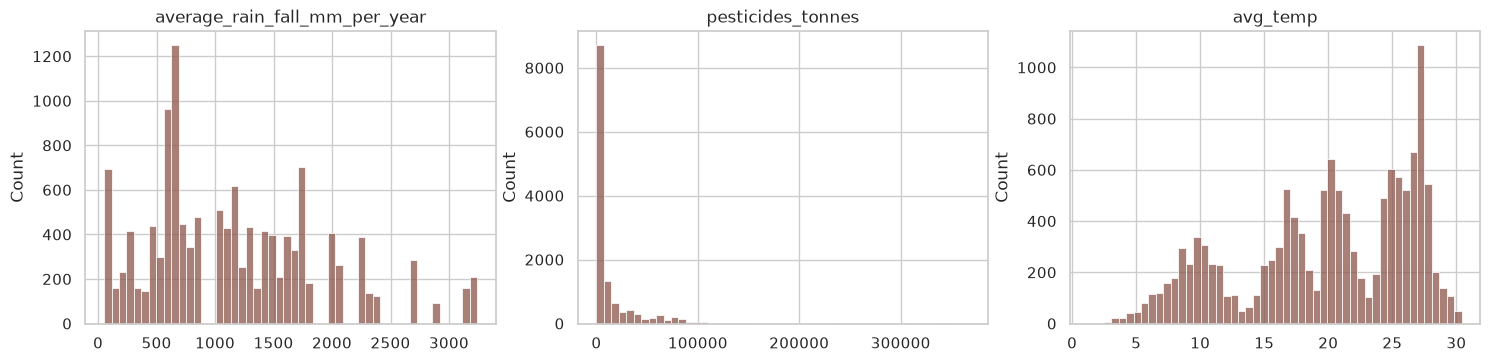

,"pesticides médians (tonnes / an, pays entier)"
Area,
Brazil,"145,552.00"
France,"84,011.00"
Italy,"81,217.60"
Japan,"78,735.45"
Argentina,"63,700.17"
Colombia,"51,435.13"
India,"46,195.00"
Ukraine,"42,129.32"


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
for ax, col in zip(axes, FAO_NUM, strict=True):
    sns.histplot(fao_u[col], bins=50, ax=ax, color="tab:brown")
    ax.set_title(col)
    ax.set_xlabel("")
save(fig, "fao_distributions_num")
plt.show()

pest_country = fao_u.groupby("Area")["pesticides_tonnes"].median().sort_values(ascending=False)
pest_country.head(8).to_frame("pesticides médians (tonnes / an, pays entier)")

**Lecture.** `pesticides_tonnes` est une **quantité totale par pays**, pas une dose par hectare : elle mesure surtout la **taille et l'intensification de l'agriculture du pays** (Brésil, France, Italie, Japon en tête), pas l'intensité d'usage sur une parcelle. Pour un agriculteur qui renseigne « sa » parcelle, cette variable est difficile à interpréter telle quelle.

➡️ *Point à arbitrer à l'étape 2* : la garder telle quelle, la passer en log, ou la remplacer par une version normalisée (par exemple ramenée à la surface agricole du pays, donnée non fournie ici).

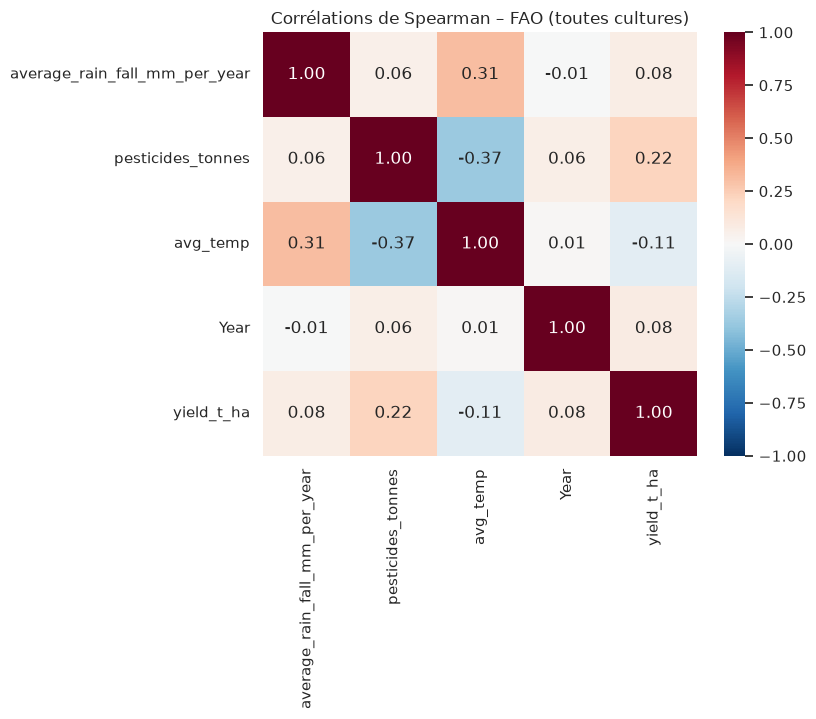

,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,Year
Item,,,,
Potatoes,-0.09,0.52,-0.38,0.20
Cassava,0.20,0.23,0.30,0.18
Plantains and others,0.22,0.51,-0.10,0.06
Yams,0.41,0.33,-0.09,0.22
Sweet potatoes,-0.13,0.45,-0.28,0.13
"Rice, paddy",-0.06,0.56,-0.32,0.19
Maize,-0.08,0.52,-0.51,0.22
Wheat,0.01,0.26,-0.45,0.13
Soybeans,0.01,0.55,-0.26,0.07


In [21]:
spearman = fao_u[FAO_NUM + ["Year", "yield_t_ha"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Corrélations de Spearman – FAO (toutes cultures)")
save(fig, "fao_corr")
plt.show()

# Les corrélations globales mélangent les cultures : on les recalcule culture par culture
by_crop = pd.DataFrame(
    {
        item: grp[FAO_NUM + ["Year"]].corrwith(grp["yield_t_ha"], method="spearman")
        for item, grp in fao_u.groupby("Item")
    }
).T
by_crop.loc[order]

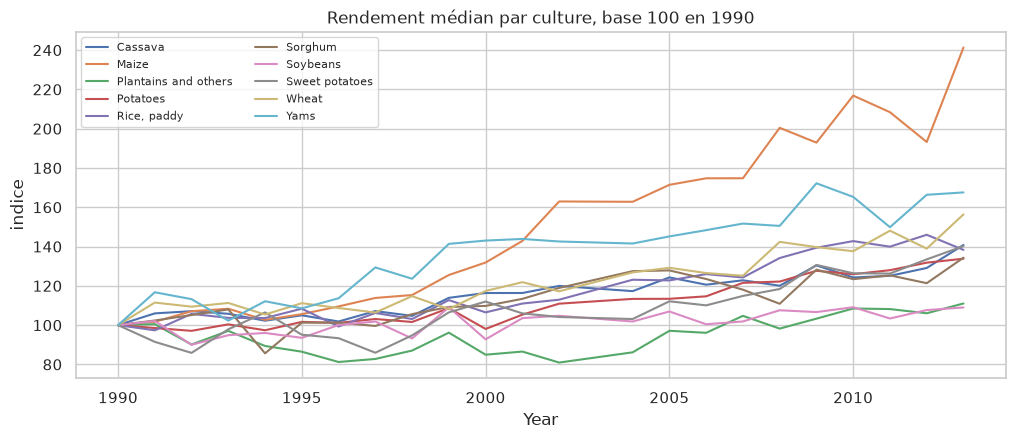

In [22]:
trend = fao_u.groupby(["Year", "Item"])["yield_t_ha"].median().unstack()
fig, ax = plt.subplots(figsize=(12, 4.5))
(trend / trend.iloc[0] * 100).plot(ax=ax, linewidth=1.5)
ax.set_title("Rendement médian par culture, base 100 en 1990")
ax.set_ylabel("indice")
ax.legend(ncol=2, fontsize=8)
save(fig, "fao_trend")
plt.show()

**Lecture.** Culture par culture :
- les **pesticides** sont la variable la plus liée au rendement, positivement pour les 10 cultures (Spearman 0,23 à 0,61). Il s'agit d'une **corrélation, pas d'un effet causal** : les pays qui en utilisent le plus sont aussi ceux dont l'agriculture est la plus mécanisée et intensive ;
- la **température** joue négativement pour la plupart des cultures (−0,51 pour le maïs, −0,45 pour le blé) mais **positivement pour le manioc** (+0,30), culture tropicale ;
- la **pluie annuelle** n'est presque pas liée au rendement (|ρ| ≤ 0,2 sauf igname) : une moyenne nationale annuelle est trop grossière pour capter l'eau disponible sur une parcelle.

Les relations sont donc **modérées et changent selon la culture** : un modèle unique devra donc pouvoir croiser culture et climat (modèles à base d'arbres, ou interactions explicites). Le rendement progresse aussi avec les années (progrès techniques) : l'année porte de l'information, mais un agriculteur prédit pour **aujourd'hui**, pas pour 1995 — à discuter à l'étape 2 (variable à exclure, ou à figer sur l'année la plus récente).

## Partie C – Cohérence entre les deux jeux

### C1. Cultures communes

In [23]:
NAME_MAP = {"Rice, paddy": "Rice", "Soybeans": "Soybean"}
kaggle_crops = set(crop["Crop"].cat.categories)
fao_crops = set(fao_u["Item"].replace(NAME_MAP))
pd.DataFrame(
    {
        "communes": [sorted(kaggle_crops & fao_crops)],
        "Kaggle seulement": [sorted(kaggle_crops - fao_crops)],
        "FAO seulement": [sorted(fao_crops - kaggle_crops)],
    }
).T.rename(columns={0: "cultures"})

,cultures
communes,"[Maize, Rice, Soybean, Wheat]"
Kaggle seulement,"[Barley, Cotton]"
FAO seulement,"[Cassava, Plantains and others, Potatoes, Sorg..."


### C2. Plages de valeurs des variables communes

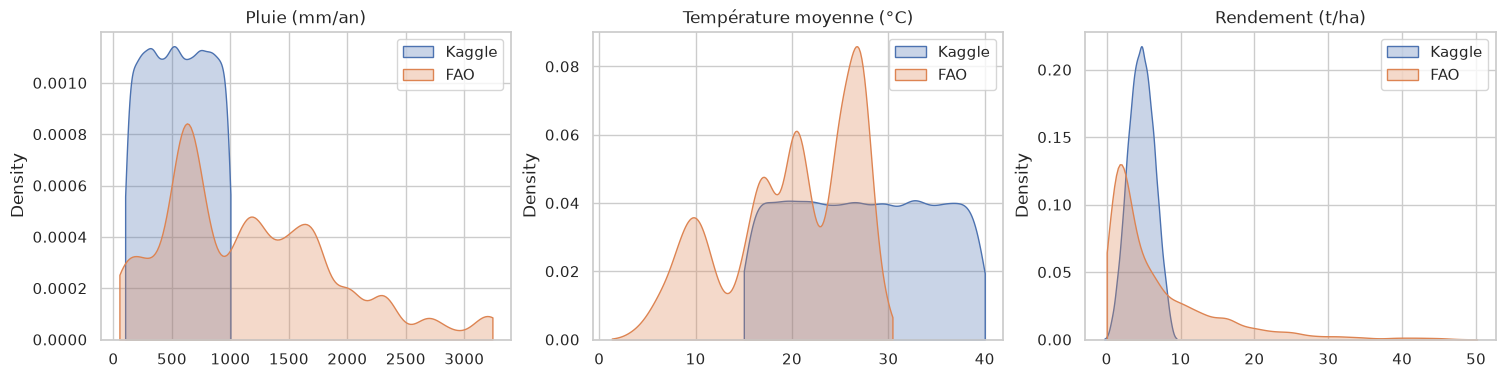

,variable,Kaggle min–max,FAO min–max
0,Pluie (mm/an),100.0 – 1000.0,51.0 – 3240.0
1,Température moyenne (°C),15.0 – 40.0,1.3 – 30.4
2,Rendement (t/ha),-1.1 – 10.0,0.0 – 50.1


In [24]:
pairs = [
    ("Pluie (mm/an)", "Rainfall_mm", "average_rain_fall_mm_per_year"),
    ("Température moyenne (°C)", "Temperature_Celsius", "avg_temp"),
    ("Rendement (t/ha)", TARGET, "yield_t_ha"),
]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
rows = []
for ax, (label, k_col, f_col) in zip(axes, pairs, strict=True):
    sns.kdeplot(sample[k_col], ax=ax, label="Kaggle", fill=True, alpha=0.3, cut=0)
    sns.kdeplot(fao_u[f_col], ax=ax, label="FAO", fill=True, alpha=0.3, cut=0)
    ax.set_title(label)
    ax.set_xlabel("")
    ax.legend()
    rows.append(
        {
            "variable": label,
            "Kaggle min–max": f"{crop[k_col].min():.1f} – {crop[k_col].max():.1f}",
            "FAO min–max": f"{fao_u[f_col].min():.1f} – {fao_u[f_col].max():.1f}",
        }
    )
save(fig, "kaggle_vs_fao_ranges")
plt.show()
pd.DataFrame(rows)

**Lecture.**
- **Cultures** : 4 cultures en commun après harmonisation des noms (`Rice, paddy` → Rice, `Soybeans` → Soybean). Orge et coton n'existent que dans Kaggle ; 6 cultures (dont les tubercules) que dans FAO.
- **Pluie** : la FAO couvre une plage bien plus large (climats tropicaux humides) que Kaggle (100–1 000 mm).
- **Température** : Kaggle va jusqu'à 40 °C de moyenne, valeur irréaliste pour une moyenne annuelle ; la FAO s'arrête vers 30 °C. Les curseurs de l'interface devront rester dans la plage **où le modèle a appris** (FAO), sinon il extrapolerait.
- **Unités** : pluie en mm et température en °C des deux côtés ; rendement à convertir côté FAO (fait ci-dessus).

## Synthèse et décisions pour `02_fusion`

| # | Constat | Décision |
|---|---|---|
| 1 | Kaggle : 231 rendements ≤ 0, tous en climat très sec | supprimer ces lignes |
| 2 | Kaggle : jeu synthétique, rendement indépendant de la culture, piloté par pluie + engrais + irrigation | ne sert **pas** à départager les cultures ; sert à mesurer l'**effet des pratiques** |
| 3 | Kaggle : gain engrais / irrigation identique pour toutes les cultures | facteur pratiques **unique**, applicable à toutes les cultures FAO |
| 4 | FAO : 15 112 lignes sur 28 242 sont des doublons de clé (relevés de température multiples) ; 13 130 observations réelles | 1 ligne par pays × culture × année, température moyenne, **avant** le découpage train/test |
| 5 | FAO : rendement en hg/ha, très asymétrique | conversion en t/ha ; tester une cible en log à l'étape 2 |
| 6 | FAO : la culture est le 1er facteur de rendement, effets climat variables selon la culture | modèle capable d'interactions culture × climat |
| 7 | FAO : pesticides = total national, pas une dose | à arbitrer à l'étape 2 (brut, log, ou exclusion) |
| 8 | Plages de valeurs différentes entre jeux | bornes de l'interface = plage FAO observée |
| 9 | Aucune donnée de prix | rentabilité : question pour le mentor |

**Variables clés pressenties** (à confirmer par l'ACP et la modélisation) :
- **données FAO** (choix de la culture) : la **culture** d'abord, puis les **pesticides** (indicateur d'intensification) et la **température** ;
- **données Kaggle** (pratiques) : la **pluie**, l'**engrais** (+38 %) et l'**irrigation** (+30 %).

Paradoxe à expliquer dans le rapport : la pluie est décisive dans Kaggle mais quasi muette dans FAO. Ce n'est pas contradictoire : la pluie FAO est une **moyenne nationale annuelle**, bien moins précise qu'une mesure à la parcelle.